# Lecture 0: Why Quantum Engineering?

[Course contents](../00_course_contents.md) | [Next lecture →](./01_introduction_and_python.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** This notebook may be downloaded, taught, adapted, and shared with attribution. It supports institutional teaching, independent study, examination review, and preparation for quantum-technology roles. See the [reuse terms](../LICENSE), [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and [citation metadata](../CITATION.cff).

This lecture develops the first chapter of A. Krasnok, *Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*.

## Learning objectives

- Explain why quantum computers complement rather than replace classical computers.
- Relate amplitudes, phase, interference, entanglement, and measurement to information processing.
- Estimate the classical memory required for a generic $n$-qubit state.
- Distinguish quantum computing, sensing, and networking, and identify their principal engineering resources and limitations.

## Core ideas

- **Quantum advantage is problem-specific.** A large state space is a resource only when an algorithm can prepare, transform, and measure it efficiently.
- **Phase becomes useful through interference.** Quantum programs steer amplitudes so desired outcomes are reinforced and undesired outcomes are suppressed.
- **Useful systems require an entire engineering stack.** Qubits, control, calibration, readout, error correction, classical processing, and verification must work together.


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

## Quantum computers do not replace classical computers

Classical computers remain the right machines for email, databases, numerical simulation, control, graphics, and most scientific workloads. Quantum computers matter for a narrower reason: molecules, spins, electrons, and photons are already quantum systems. Their states evolve through complex amplitudes and phases, and direct classical representations of generic many-body states can become impractically large.

A quantum processor is therefore best viewed as a **specialized physical coprocessor**. It may offer an advantage when all three conditions hold:

1. a problem has exploitable quantum structure;
2. a quantum algorithm reaches the answer with fewer relevant resources than the best classical method; and
3. the full implementation cost—including state preparation, error correction, repetitions, and data movement—does not erase that advantage.

The phrase *quantum advantage* should always name the task, input model, accuracy target, resource measure, hardware assumptions, and classical baseline.


## From semiconductor scaling to quantum engineering

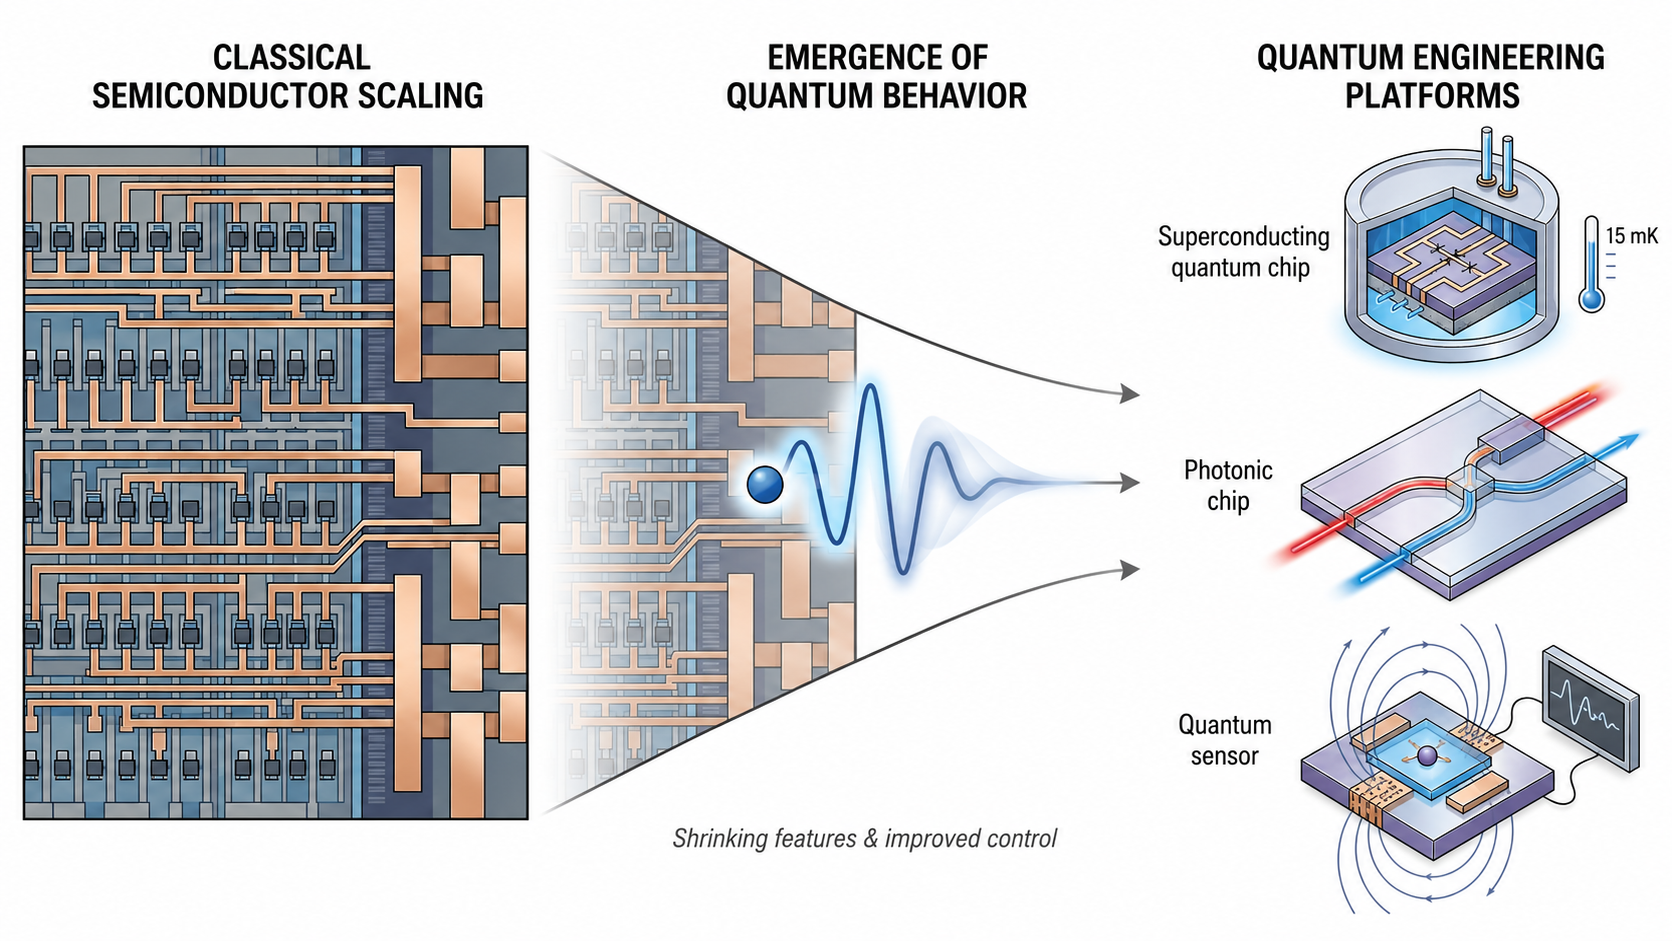

*Shrinking features and improving control pushed devices into regimes where quantum behavior could no longer be ignored. The same fabrication, cryogenic, optical, microwave, and measurement capabilities now support deliberately engineered superconducting circuits, photonic processors, and quantum sensors. The diagram describes a historical and technological transition; it does not imply that one platform is universally superior.*


## The state-space scaling challenge

A classical bit stores one definite value, 0 or 1. A qubit is described by two complex amplitudes. A general pure state of $n$ qubits requires one amplitude for each computational-basis string:

$$
N_{\mathrm{amp}}=2^n.
$$

If each complex amplitude is stored as two 64-bit floating-point numbers, the raw statevector memory is approximately

$$
M_{\mathrm{bytes}}=16\times 2^n.
$$

This is the memory for the statevector alone. A simulator may require additional storage for temporary arrays, operators, communication buffers, and bookkeeping. A dense $2^n\times2^n$ operator is even more demanding, scaling as $4^n$ complex entries.


In [2]:
def statevector_memory(qubits: int, bytes_per_amplitude: int = 16) -> int:
    # Raw bytes needed for a dense complex statevector.
    return bytes_per_amplitude * 2**qubits


print(f"{'qubits':>6} {'amplitudes':>18} {'decimal storage':>22}")
for qubits in (20, 30, 40, 50, 60, 100):
    amplitudes = 2**qubits
    storage = statevector_memory(qubits)
    if storage < 10**12:
        label = f"{storage / 10**9:,.3f} GB"
    elif storage < 10**15:
        label = f"{storage / 10**12:,.3f} TB"
    elif storage < 10**18:
        label = f"{storage / 10**15:,.3f} PB"
    else:
        label = f"{storage / 10**18:,.3e} EB"
    print(f"{qubits:6d} {amplitudes:18,d} {label:>22}")

qubits         amplitudes        decimal storage
    20          1,048,576               0.017 GB
    30      1,073,741,824              17.180 GB
    40  1,099,511,627,776              17.592 TB
    50 1,125,899,906,842,624              18.014 PB
    60 1,152,921,504,606,846,976           1.845e+01 EB
   100 1,267,650,600,228,229,401,496,703,205,376           2.028e+13 EB


### Exponential description is not automatic speedup

The $2^n$ state-space dimension is a warning about generic dense classical representations, not a proof that every quantum calculation is classically hard. Classical methods can exploit structure such as locality, symmetry, sparsity, low entanglement, stabilizer form, or tensor-network compressibility. Conversely, a quantum algorithm can fail to produce an advantage if it requires expensive input loading, deep circuits, too many samples, or an output containing exponentially many classical numbers.

> **Engineering test:** compare end-to-end resources for the best known classical and quantum approaches at the same accuracy and success probability.


## Five ideas that organize the course

| Idea | Mathematical role | Engineering interpretation |
|---|---|---|
| **Amplitude** | A complex coefficient whose squared magnitude contributes to an outcome probability | A quantity controlled indirectly by pulses, gates, and interactions |
| **Phase** | The complex angle of an amplitude | Information that becomes observable only relative to another amplitude or reference |
| **Interference** | Coherent addition of amplitudes | A mechanism for enhancing some outcomes and suppressing others |
| **Entanglement** | A joint state that cannot be written as a product of subsystem states | A nonclassical correlation resource, but also a source of simulation difficulty and control demands |
| **Measurement** | A probabilistic quantum-to-classical interface | A physical readout with finite efficiency, noise, calibration error, and limited information per shot |

Measurement does not reveal the complete statevector in one run. Reconstructing an unknown state generally requires many preparations and measurements in multiple settings.


## A qubit as a geometric state

Ignoring an unobservable global phase, every pure qubit state can be written as

$$
\lvert\psi\rangle=
\cos\!\left(\frac{\theta}{2}\right)\lvert0\rangle+
e^{i\phi}\sin\!\left(\frac{\theta}{2}\right)\lvert1\rangle,
$$

where $0\leq\theta\leq\pi$ and $0\leq\phi<2\pi$. The computational-basis probabilities are

$$
P(0)=\cos^2\!\left(\frac{\theta}{2}\right),\qquad
P(1)=\sin^2\!\left(\frac{\theta}{2}\right).
$$

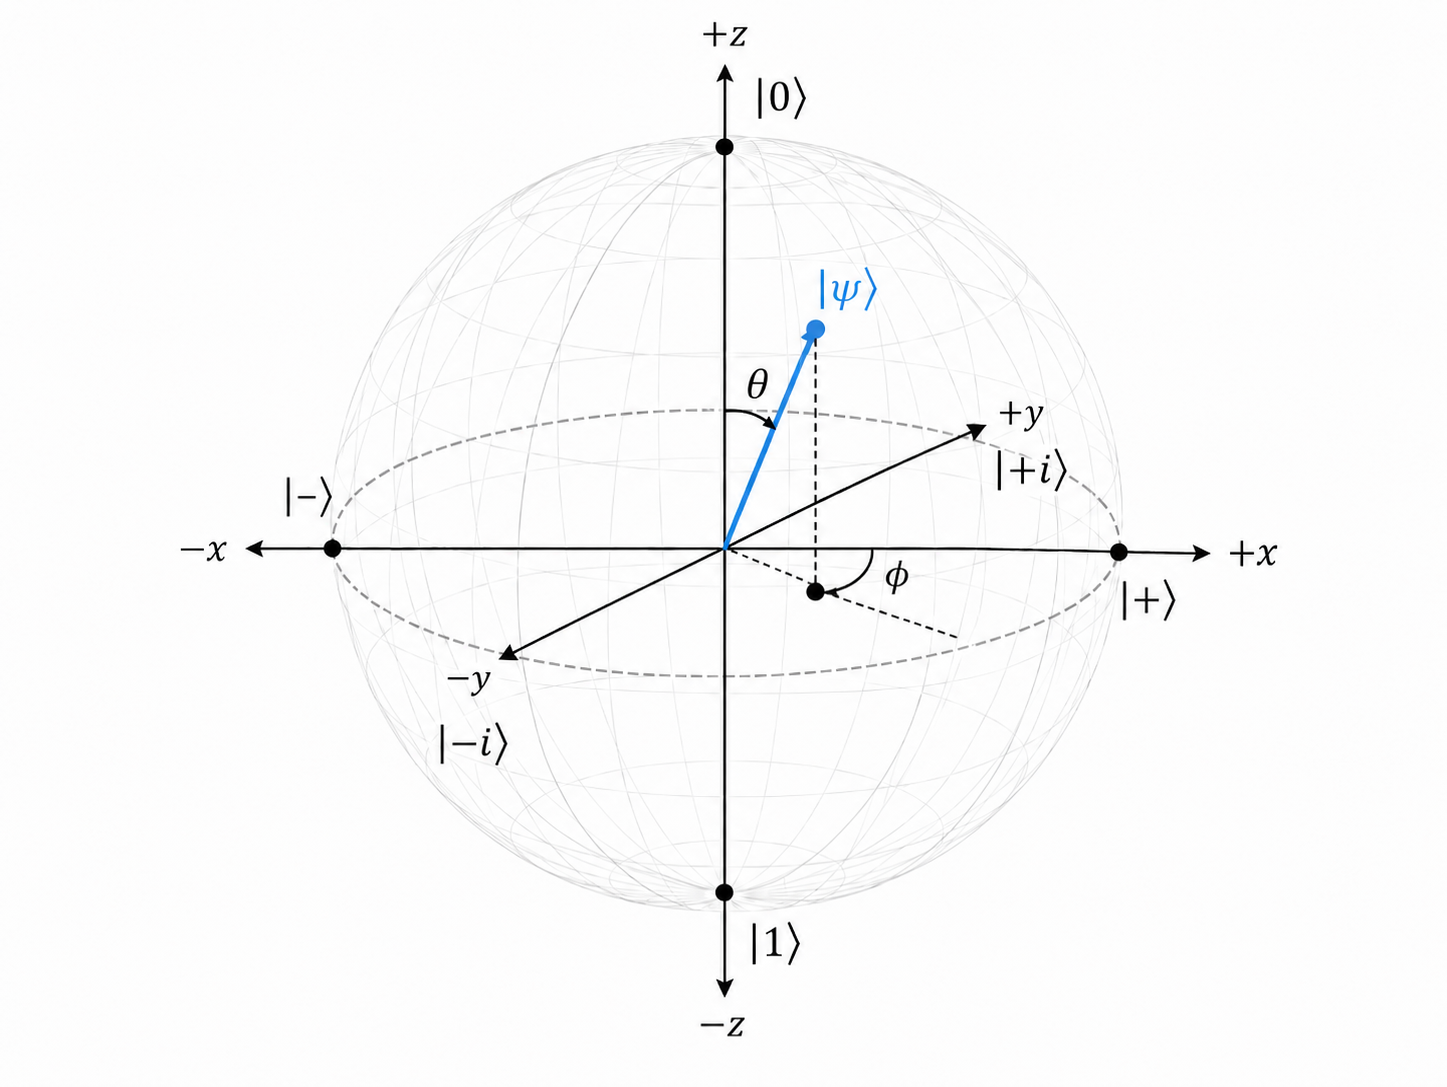

*The north and south poles represent $\lvert0\rangle$ and $\lvert1\rangle$. Equatorial points represent equal-magnitude superpositions with different relative phases. The blue vector locates an arbitrary pure state by polar angle $\theta$ and azimuthal angle $\phi$. A mixed state lies inside the sphere rather than on its surface.*


In [3]:
theta = 2 * np.arccos(np.sqrt(0.8))
relative_phase = np.pi / 3
psi = np.array(
    [np.cos(theta / 2), np.exp(1j * relative_phase) * np.sin(theta / 2)],
    dtype=complex,
)

probabilities = np.abs(psi) ** 2
print("state =", psi)
print("norm squared =", np.vdot(psi, psi).real)
print("P(0), P(1) =", probabilities)

assert np.allclose(np.vdot(psi, psi), 1.0)
assert np.allclose(probabilities, [0.8, 0.2])

state = [0.89442719+0.j         0.2236068 +0.38729833j]
norm squared = 1.0
P(0), P(1) = [0.8 0.2]


## Interference is controlled amplitude bookkeeping

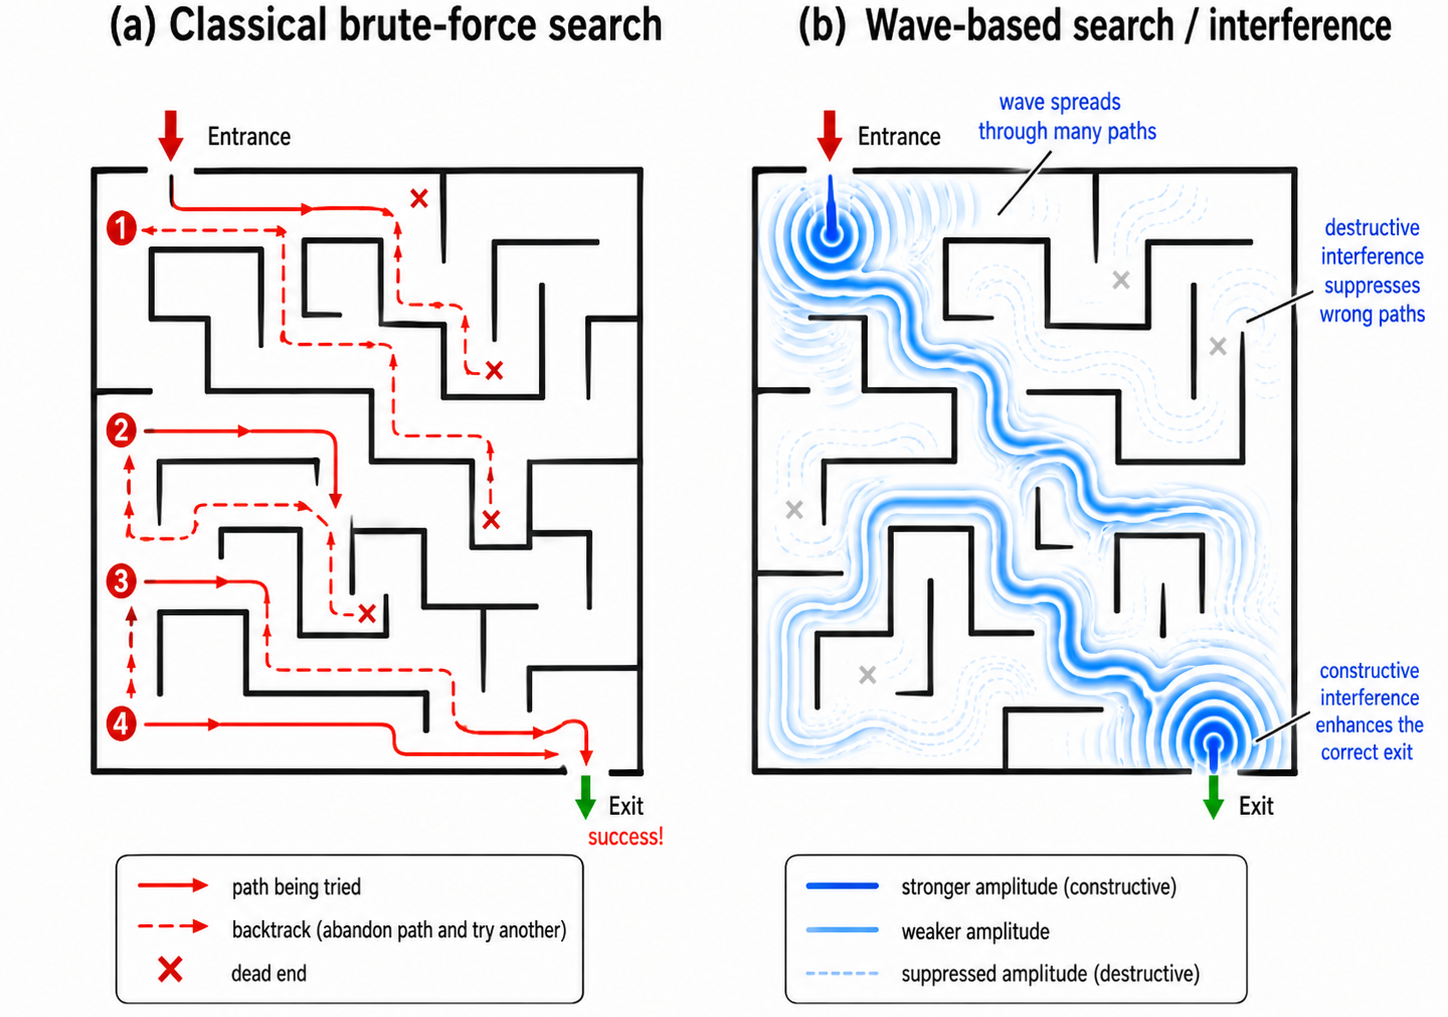

*The left panel represents a classical depth-first search that tries a path, encounters a dead end, and backtracks. The right panel uses wave propagation as an analogy: amplitudes spread through multiple paths, destructive interference suppresses selected routes, and constructive interference strengthens a selected exit.*

> **Important limitation of the analogy:** an uncontrolled physical wave does not solve an arbitrary maze, and a quantum computer does not simply try every answer and read them all out. A valid quantum algorithm must encode the problem, implement coherent transformations that create the required phase relationships, and finish with a measurement whose success probability is high enough. Oracle construction and state preparation are part of the cost.


## Converting phase into a measurable probability

A single-qubit interferometer illustrates the central pattern:

$$
\lvert0\rangle\xrightarrow{H}\lvert+\rangle
\xrightarrow{R_z(\varphi)}R_z(\varphi)\lvert+\rangle
\xrightarrow{H}
\cos\!\left(\frac{\varphi}{2}\right)\lvert0\rangle
-i\sin\!\left(\frac{\varphi}{2}\right)\lvert1\rangle.
$$

The final global phase convention does not affect the probabilities:

$$
P(0)=\cos^2\!\left(\frac{\varphi}{2}\right),\qquad
P(1)=\sin^2\!\left(\frac{\varphi}{2}\right).
$$

The first Hadamard creates two coherent alternatives. The $z$ rotation changes their relative phase. The second Hadamard recombines them, converting phase into a population difference that can be measured.


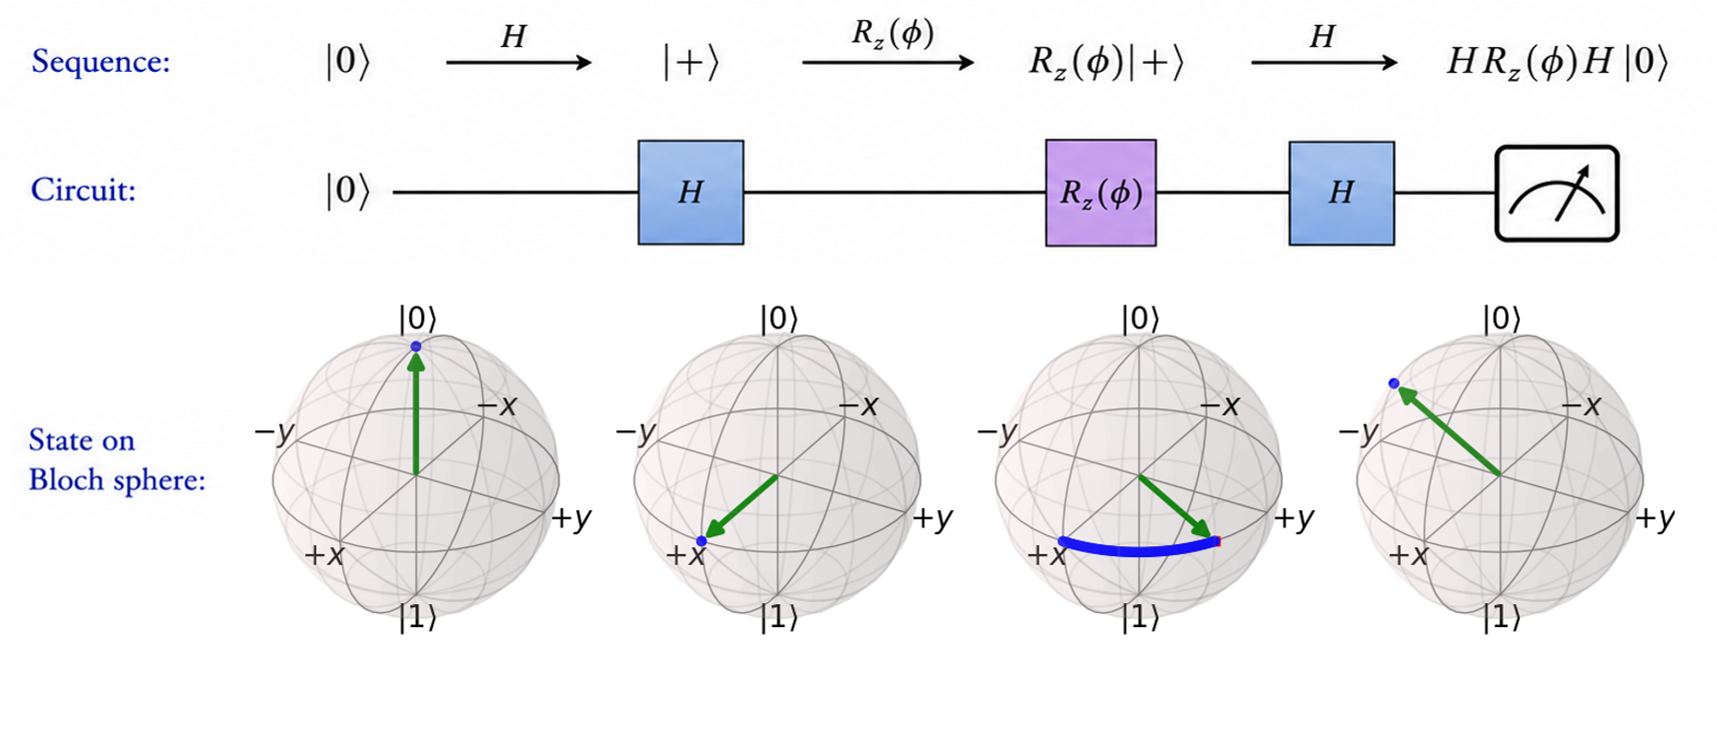

*The upper rows show the state sequence and equivalent circuit. The lower row follows the Bloch vector from $\lvert0\rangle$ to an equatorial superposition, through a phase rotation about the $z$ axis, and through the final Hadamard rotation before measurement. This is both a basic interference experiment and the core of a Ramsey-style quantum sensor.*


In [4]:
phase = np.pi / 3
interferometer = QuantumCircuit(1)
interferometer.h(0)
interferometer.rz(phase, 0)
interferometer.h(0)

final_state = Statevector.from_instruction(interferometer)
qiskit_probabilities = final_state.probabilities()
analytic_probabilities = np.array(
    [np.cos(phase / 2) ** 2, np.sin(phase / 2) ** 2]
)

print(interferometer.draw("text"))
print("final state:", final_state.data)
print("Qiskit probabilities:", qiskit_probabilities)
print("analytic probabilities:", analytic_probabilities)

assert np.allclose(qiskit_probabilities, analytic_probabilities)

   ┌───┐┌─────────┐┌───┐
q: ┤ H ├┤ Rz(π/3) ├┤ H ├
   └───┘└─────────┘└───┘
final state: [0.8660254+0.j  0.       -0.5j]
Qiskit probabilities: [0.75 0.25]
analytic probabilities: [0.75 0.25]


## Why the same sequence is useful for sensing

Suppose an external field produces a relative phase

$$
\varphi=\gamma B t,
$$

where $\gamma$ is a coupling coefficient, $B$ is the field to estimate, and $t$ is the interaction time. The interferometer maps this phase to a measurable probability. Repeating the experiment estimates $B$ from observed frequencies.

Longer interaction can increase phase accumulation, but only while coherence is preserved. Sensitivity therefore depends on a balance among coupling strength, coherence time, preparation and readout fidelity, number of repetitions, and technical noise. Quantum sensing does not remove noise; it engineers a controlled response to the desired signal while suppressing unwanted disturbances.


## How the field developed

| Year | Milestone | Engineering significance |
|---:|---|---|
| 1965 | Moore documents rapid integrated-circuit scaling | Miniaturization drives classical capability and eventually exposes unavoidable quantum-scale effects |
| 1982 | Feynman connects quantum physics with computation | Native quantum dynamics becomes a computational model for simulating quantum systems |
| 1985 | Deutsch formulates a universal quantum computer | Quantum computation becomes a general model rather than only a special-purpose simulator |
| 1994 | Shor gives efficient quantum algorithms for factoring and discrete logarithms | Quantum algorithms become directly relevant to complexity theory and public-key cryptography |
| 1996 | Grover gives a quadratic query advantage for unstructured search | Interference is shown to reduce ideal oracle queries from order $N$ to order $\sqrt N$ |
| 2018 | Preskill defines the NISQ era | The field distinguishes noisy experimental processors from future fault-tolerant systems |

These milestones mix different resource models. An asymptotic query advantage does not specify the number of physical qubits, gates, error-correction cycles, samples, or seconds required by an implementation.


## Physical qubits, logical qubits, and fault tolerance

- A **physical qubit** is a laboratory degree of freedom used to encode a two-level computational system: for example, a superconducting circuit, trapped ion, neutral atom, spin, or photonic mode.
- A **logical qubit** is quantum information encoded across multiple physical components so that errors can be detected and corrected without directly measuring the protected logical state.
- **Fault tolerance** is a system property: error-corrected operations, measurements, state preparation, and classical decoding are organized so that increasing the code scale can suppress logical failure below the level required by the computation.

Qubit count alone is therefore not a complete performance metric. Relevant system measures include gate and measurement errors, connectivity, leakage, coherence, cycle time, calibration stability, decoder latency, logical error per operation, and the space-time cost of the target algorithm.


## The NISQ engineering regime

Noisy intermediate-scale quantum processors support valuable experiments, calibration research, control development, and small demonstrations. Their circuits remain limited by imperfect gates, readout error, loss, leakage, crosstalk, drift, and finite coherence.

NISQ hardware is not equivalent to a fault-tolerant computer. Error mitigation can reduce some biases by combining additional measurements and modeling assumptions, but it does not supply the scalable protection guaranteed by quantum error correction. Claims of practical usefulness must therefore report the classical comparison, uncertainty, resource cost, and conditions under which the result was obtained.


## Computing, sensing, and networking

| Domain | Primary question | Central resources | Dominant limitations |
|---|---|---|---|
| **Quantum computing** | How can controlled evolution produce a useful classical answer? | Gates, interference, entanglement, measurement, error correction | Gate errors, readout errors, leakage, crosstalk, depth, and logical overhead |
| **Quantum sensing** | How can a quantum state estimate a field, force, frequency, time, or motion? | Coherence, phase accumulation, controlled coupling, repeated estimation | Decoherence, technical noise, calibration, finite sampling, and readout efficiency |
| **Quantum networking** | How can quantum states or entanglement be distributed between remote nodes? | Photons, matter–light interfaces, memories, heralding, entanglement swapping | Optical loss, detector noise, memory lifetime, conversion efficiency, and timing |

All three domains use the same mathematical language. Their engineering objectives differ: computing protects and transforms information, sensing deliberately couples a state to a signal, and networking transports states or correlations without learning the encoded quantum information in transit.


## What quantum computers can and cannot do

| Quantum computers can, in principle… | Quantum computers do not… |
|---|---|
| Simulate selected quantum systems using native quantum degrees of freedom | Replace classical computers for ordinary workloads |
| Provide proven asymptotic advantages for specific mathematical problems | Make every optimization, search, or machine-learning problem easy |
| Use interference and entanglement as algorithmic resources | Reveal all $2^n$ amplitudes in one measurement |
| Work as accelerators inside hybrid scientific workflows | Repair a poor model, biased data, or an ill-posed question |
| Improve selected sensing and communication protocols | Eliminate physical noise, loss, calibration, or verification requirements |

The most credible application statement is conditional: **for this task, input model, accuracy, and hardware model, this quantum procedure uses fewer specified resources than the best relevant classical alternative.**


## Simulator results and hardware results answer different questions

An ideal statevector simulator verifies the mathematics of a circuit under an exact model. A shot-based ideal simulator adds sampling fluctuations. A noisy simulator evaluates a chosen error model. A physical processor adds device-specific calibration, drift, crosstalk, leakage, latency, and control constraints.

| Evidence | What it supports | What it does not establish |
|---|---|---|
| Exact statevector agreement | The circuit implements the intended ideal linear algebra | Hardware fidelity or scalability |
| Finite-shot ideal counts | Expected statistical variation under ideal sampling | Physical noise performance |
| Noise-model simulation | Consequences of the modeled channels and parameters | Accuracy of an unvalidated device model |
| Hardware experiment | Performance of a particular device and calibration at a particular time | Universal performance across devices, dates, or larger scales |

Reproducible quantum engineering records the circuit, software versions, backend, compiler settings, number of shots, calibration context, uncertainty, and analysis procedure.


## Course map

- **Lectures 1–3:** reproducible Python, linear algebra, complex amplitudes, operators, and Dirac notation.
- **Lectures 4–6:** Hilbert spaces, measurement, dynamics, density operators, decoherence, and entanglement.
- **Lectures 7–8:** Bloch-sphere geometry, gates, circuits, current Qiskit, simulation, sampling, and compilation.
- **Lectures 9–10:** teleportation, Grover search, phase kickback, Fourier methods, phase estimation, and order finding.
- **Lectures 11–12:** hardware architectures, photonics, superconducting qubits, control, readout, error correction, and system-resource budgets.

The [Python primer](../appendices/python_primer.ipynb) can be completed before Lecture 1 or used as a reference throughout the course.


## Readiness checks

1. Calculate the raw memory required for a 60-qubit dense statevector at 16 bytes per amplitude. State the answer in decimal exabytes.
2. For an ideal unstructured search with one marked item and $N=10^6$, compare the scaling estimates $N$ and $\sqrt N$. List at least three implementation costs omitted by this comparison.
3. For the $H$–$R_z(\varphi)$–$H$ sequence, evaluate $P(0)$ and $P(1)$ at $\varphi=0$, $\pi/2$, and $\pi$.
4. Explain why an exponentially large state space is neither necessary nor sufficient evidence of a useful quantum speedup.
5. Give one example in which environmental coupling is an unwanted noise source for a quantum computer but the desired signal for a quantum sensor.


## Key takeaways

- Quantum processors are specialized physical coprocessors, not replacements for classical computers.
- A generic $n$-qubit state needs $2^n$ complex amplitudes in a dense classical representation, but exploitable structure can make some states classically tractable.
- Phase is useful only through controlled interference, and measurement returns limited classical information.
- Quantum computing, sensing, and networking share the same physics while optimizing different resources.
- Reliable quantum computation is a system-engineering problem centered on logical performance, not raw physical-qubit count alone.
- Every advantage claim needs a task, accuracy target, resource model, hardware assumptions, and classical baseline.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. R. P. Feynman, [“Simulating Physics with Computers,”](https://doi.org/10.1007/BF02650179) *International Journal of Theoretical Physics* **21**, 467–488 (1982).
2. D. Deutsch, [“Quantum Theory, the Church–Turing Principle and the Universal Quantum Computer,”](https://doi.org/10.1098/rspa.1985.0070) *Proceedings of the Royal Society A* **400**, 97–117 (1985).
3. P. W. Shor, [“Algorithms for Quantum Computation: Discrete Logarithms and Factoring,”](https://doi.org/10.1109/SFCS.1994.365700) *Proceedings of the 35th Annual Symposium on Foundations of Computer Science*, 124–134 (1994).
4. L. K. Grover, [“A Fast Quantum Mechanical Algorithm for Database Search,”](https://doi.org/10.1145/237814.237866) *Proceedings of STOC '96*, 212–219 (1996).
5. J. Preskill, [“Quantum Computing in the NISQ Era and Beyond,”](https://quantum-journal.org/papers/q-2018-08-06-79/) *Quantum* **2**, 79 (2018).
6. C. L. Degen, F. Reinhard, and P. Cappellaro, [“Quantum Sensing,”](https://doi.org/10.1103/RevModPhys.89.035002) *Reviews of Modern Physics* **89**, 035002 (2017).
7. H. J. Kimble, [“The Quantum Internet,”](https://doi.org/10.1038/nature07127) *Nature* **453**, 1023–1030 (2008).
8. IBM Quantum, [`RZGate`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.RZGate) and [`Statevector`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector) documentation.
